# Experiment 3: House Price Prediction using Linear Regression
**Aim:** To develop a Linear Regression model for predicting house prices, evaluate its performance, and predict the price of a new house.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### A) Dataset Loading and Inspection

In [5]:
# Load dataset (update path if needed, e.g., '../Datasets/house_prices_dataset.csv')
df = pd.read_csv("../Datasets/house_prices_dataset.csv")

print("Shape:", df.shape)
print(df.head())
print("\nMissing Values:\n", df.isnull().sum())

Shape: (150, 4)
   SquareFootage  NumBedrooms  AgeOfHouse   Price
0           3674            3          18  481447
1           1360            3          82  161140
2           1794            1          66  209513
3           1630            3          54  195619
4           1595            5          35  221977

Missing Values:
 SquareFootage    0
NumBedrooms      0
AgeOfHouse       0
Price            0
dtype: int64


### B) Model Training and Evaluation

In [6]:
X = df[["SquareFootage", "NumBedrooms", "AgeOfHouse"]]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mse)
print("RMSE:", np.sqrt(mse))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 10199.426547832214
MSE: 146415745.8892372
RMSE: 12100.237431110068
R2 Score: 0.9900879804000002


### C) Visualization and Price Prediction

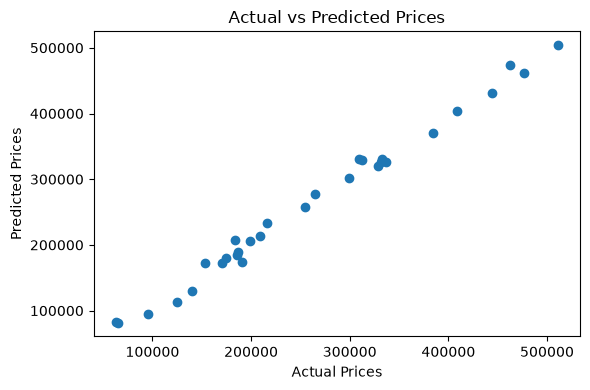

Predicted House Price: $326,369.87


In [7]:
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
plt.tight_layout()
plt.show()

# Example: 2000 sq. ft., 10 bedrooms, 3 years old
house = pd.DataFrame(
    [[2000, 10, 3]],
    columns=["SquareFootage", "NumBedrooms", "AgeOfHouse"]
)
price = model.predict(scaler.transform(house))
print(f"Predicted House Price: ${price[0]:,.2f}")